In [539]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os
import warnings
import itertools

from scipy.stats import kurtosis
import plotly.express as px

from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

import nltk
nltk.download('punkt')
nltk.download('wordnet')
from nltk.corpus import stopwords
import re
from nltk.stem import WordNetLemmatizer

warnings.filterwarnings('ignore', category=DeprecationWarning)

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\jshap\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\jshap\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


EDA

In [540]:
# Set filepath to working directory
path = 'C:\\Users\\jshap\\OneDrive\\Desktop\\BBC\\'

We have three files to work with here, a submission sample, a training set, and a testing set. Let's read each of them in and see what structure, size, and data type we're dealing with.

In [541]:
# Read data in
train = pd.read_csv(path + 'BBC News Train.csv', delimiter = ',', engine = 'python')
train.head()

,ArticleId,Text,Category
0,1833,worldcom ex-boss launches defence lawyers defe...,business
1,154,german business confidence slides german busin...,business
2,1101,bbc poll indicates economic gloom citizens in ...,business
3,1976,lifestyle governs mobile choice faster bett...,tech
4,917,enron bosses in $168m payout eighteen former e...,business


In [542]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1490 entries, 0 to 1489
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   ArticleId  1490 non-null   int64 
 1   Text       1490 non-null   object
 2   Category   1490 non-null   object
dtypes: int64(1), object(2)
memory usage: 35.0+ KB


Our training data is 1490 rows by only 3 columns, which appears to leave very little to work with for model building at first glance, especially considering one column is simply a meaningless ID value and one is the article category. However, we have the ability to generate a significant amount of information from the text column. We'll circle back on how to do that after we finish checking out all of the files.

In [543]:
size = train.shape

for col in train.columns:
    missing = train[col].isna().sum()
    unique = train[col].nunique()
    print(f"Missing values in feature '{col}': {missing} out of {size[0]}, or {round(100 * missing / size[0], 1)}% missing")
    print(f"Unique values in feature '{col}': {unique} out of {size[0]}, or {round(100 * unique / size[0], 1)}% unique")
    print()

Missing values in feature 'ArticleId': 0 out of 1490, or 0.0% missing
Unique values in feature 'ArticleId': 1490 out of 1490, or 100.0% unique

Missing values in feature 'Text': 0 out of 1490, or 0.0% missing
Unique values in feature 'Text': 1440 out of 1490, or 96.6% unique

Missing values in feature 'Category': 0 out of 1490, or 0.0% missing
Unique values in feature 'Category': 5 out of 1490, or 0.3% unique



Excellent! Our dataset is not missing any values, so we need not employ any form of imputation or row/column deletion in that respect. Interestingly, although every article has a unique ID, implying that there are no duplicates, there appear to be 50 rows of text that are not unique. Although it may not cause issues in the proceeding steps, we will simply remove the duplicates for maximal technical precision.

In [544]:
train = train.drop_duplicates(subset = ["Text"], keep = "first")

# Rerun data investigation
size = train.shape

for col in train.columns:
    missing = train[col].isna().sum()
    unique = train[col].nunique()
    print(f"Missing values in feature '{col}': {missing} out of {size[0]}, or {round(100 * missing / size[0], 1)}% missing")
    print(f"Unique values in feature '{col}': {unique} out of {size[0]}, or {round(100 * unique / size[0], 1)}% unique")
    print()

Missing values in feature 'ArticleId': 0 out of 1440, or 0.0% missing
Unique values in feature 'ArticleId': 1440 out of 1440, or 100.0% unique

Missing values in feature 'Text': 0 out of 1440, or 0.0% missing
Unique values in feature 'Text': 1440 out of 1440, or 100.0% unique

Missing values in feature 'Category': 0 out of 1440, or 0.0% missing
Unique values in feature 'Category': 5 out of 1440, or 0.3% unique



All of the dupes have been successfully pruned from our training set! We can also see that there are five given categories, so let's check and see what those are and get a graphical representation of the percentages of the whole that each category makes up.

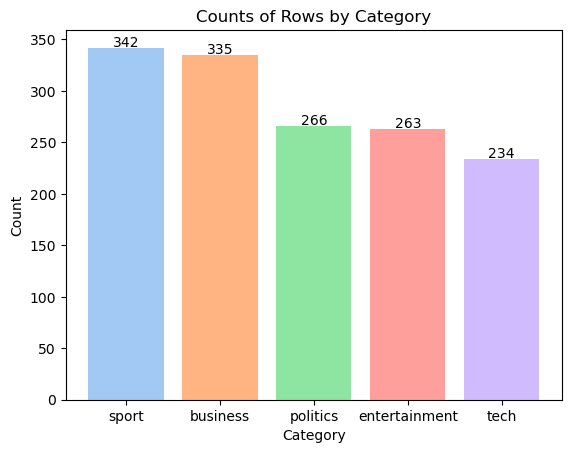

In [545]:
# Count the number of rows for each category
counts = train["Category"].value_counts()

# Plot the counts
color = sns.color_palette("pastel", len(counts))
plt.bar(counts.index, counts.values, color = color)

# Add counts above bars
for i, v in enumerate(counts.values):
    plt.text(i, v+1, str(v), ha = "center")

# Add labels
plt.xlabel("Category")
plt.ylabel("Count")
plt.title("Counts of Rows by Category")

# Display plot
plt.show()

Fortunately, we have a relatively balanced spread of articles for each category, so we shouldn't run into any issues with unbalanced class sizes leading to model instability. The next thing we would like to look at is how long the texts in the articles are, and potentially remove any outliers that are too short to convey much info or those that are unnecessarily long.

In [546]:
# get the length of each string in the 'Text' column
text_lengths = train['Text'].str.len()

# count the number of rows for each length
counts = text_lengths.value_counts()

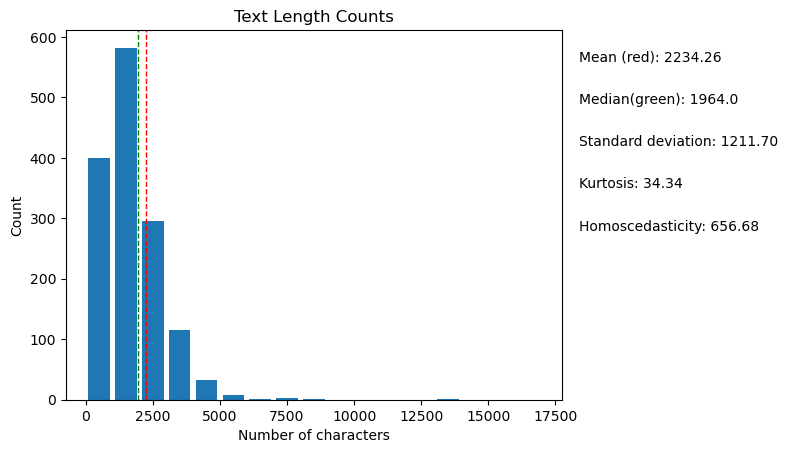

In [547]:
# Plot the counts as a histogram
plt.hist(text_lengths, bins = range(min(text_lengths), max(text_lengths)+2, 1000), align = 'left', rwidth = 0.8)

# Statistical calculations
mean_length = text_lengths.mean()
median_length = text_lengths.median()
std_length = text_lengths.std()
kurtosis_length = kurtosis(text_lengths)
homosced_length = np.var(text_lengths) / mean_length

# Vertical lines for the mean and median
plt.axvline(mean_length, color='r', linestyle = 'dashed', linewidth = 1)
plt.axvline(median_length, color='g', linestyle = 'dashed', linewidth = 1)

# Labels
plt.xlabel("Number of characters")
plt.ylabel("Count")
plt.title("Text Length Counts")

# Side text
plt.text(max(text_lengths), max(plt.yticks()[0]) * 0.8, f"Mean (red): {mean_length:.2f}")
plt.text(max(text_lengths), max(plt.yticks()[0]) * 0.7, f"Median(green): {median_length}")
plt.text(max(text_lengths), max(plt.yticks()[0]) * 0.6, f"Standard deviation: {std_length:.2f}")
plt.text(max(text_lengths), max(plt.yticks()[0]) * 0.5, f"Kurtosis: {kurtosis_length:.2f}")
plt.text(max(text_lengths), max(plt.yticks()[0]) * 0.4, f"Homoscedasticity: {homosced_length:.2f}")

# show the plot
plt.show()

The distribution of text lengths is moderately right skewed, causing the median to be a couple hundred characters fewer than the mean number of characters. While some of the articles are a bit long, only two of them are outrageous to the point where removing them would make sense, so let's put a hardcut down and limit the number of characters in an article to be 10000. 

In [548]:
# Filter out largest outliers
train = train[train['Text'].str.len() <= 10000]

# Fill in missing indices from filtration
train = train.reset_index(drop = True)

train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1437 entries, 0 to 1436
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   ArticleId  1437 non-null   int64 
 1   Text       1437 non-null   object
 2   Category   1437 non-null   object
dtypes: int64(1), object(2)
memory usage: 33.8+ KB


Let's check on the text length distributions bucketed by each of the available article categories.

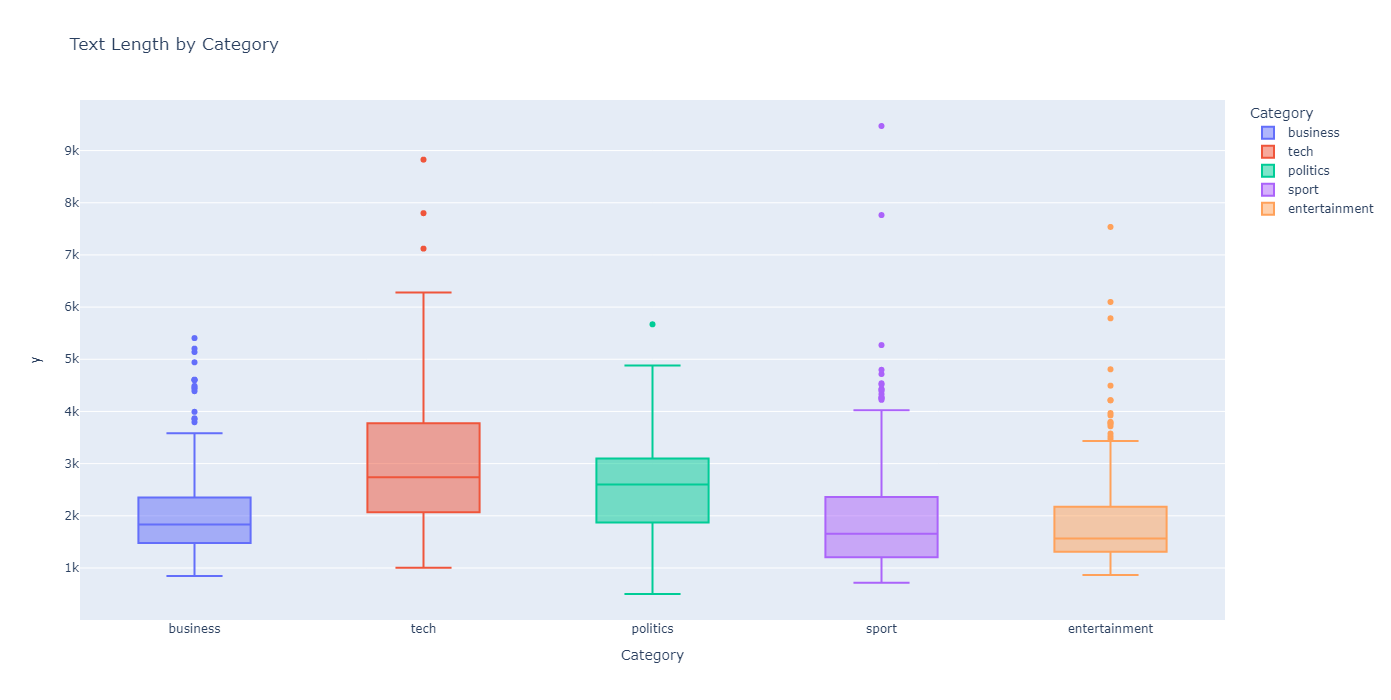

In [549]:
text_lengths = train['Text'].str.len()
fig = px.box(train, x = 'Category', y = text_lengths, color = 'Category', title = 'Text Length by Category', height = 700)
fig.show()

Tech has the highest median characters in its articles, closely followed by politics. Business is in the middle of the pack, while sport and entertainment are rounding out the bottom end. Perhaps unsurprisingly, the more nuanced the topic is in general, the longer the articles appear to be on average. Let's move on and check on the test and sample files.

In [550]:
test = pd.read_csv(path + '\\BBC News Test.csv', delimiter = ',', engine = 'python')
test.head()

,ArticleId,Text
0,1018,qpr keeper day heads for preston queens park r...
1,1319,software watching while you work software that...
2,1138,d arcy injury adds to ireland woe gordon d arc...
3,459,india s reliance family feud heats up the ongo...
4,1020,boro suffer morrison injury blow middlesbrough...


In [551]:
size = test.shape

for col in test.columns:
    missing = test[col].isna().sum()
    print(f"Missing values in feature '{col}': {missing} out of {size[0]}, or {round(100 * missing / size[0], 1)}% missing")
    print(f"Unique values in feature '{col}': {unique} out of {size[0]}, or {round(100 * unique / size[0], 1)}% unique")

Missing values in feature 'ArticleId': 0 out of 735, or 0.0% missing
Unique values in feature 'ArticleId': 5 out of 735, or 0.7% unique
Missing values in feature 'Text': 0 out of 735, or 0.0% missing
Unique values in feature 'Text': 5 out of 735, or 0.7% unique


Like the training set, our test set fortunately doesn't have any issues with missing data. Note that the dimensions are 735 rows by 2 columns now, as we no longer have the 'Category' column, leaving us with approximately a 67/33 training/test split to work with.

In [552]:
sample = pd.read_csv(path + '\\BBC News Sample Solution.csv', delimiter = ',', engine = 'python')
sample.head()

,ArticleId,Category
0,1018,sport
1,1319,tech
2,1138,business
3,459,entertainment
4,1020,politics


In [553]:
sample.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 735 entries, 0 to 734
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   ArticleId  735 non-null    int64 
 1   Category   735 non-null    object
dtypes: int64(1), object(1)
memory usage: 11.6+ KB


The sample submission file appears to have the same structure as test with the 'text' column removed, giving the sample submission 735 rows and 2 columns. Now that we have thoroughly examined our data, our plan for the next steps solidifies. We will need to perform feature extraction on the article texts for each observation in order to transform these raw characters into a format that can be easily digested by unsupervised learning techniques.

Feature Extraction

The first step we should focus on is cleaning up the text so that can be tokenized easily. This involves removing characters that aren't in the English alphabet and removing 'stop words', which are common words that add little to no value, such as 'in' or 'the'. We will use the power of regular expression to filter our text out to just letters, and then use the nltk package to import a list of stop words that we can use to further filter out unimportant words.

In [554]:
def cleaner(df, col):
    #remove non-English standard alphabetic chars
    df['letters'] = df[col].apply(lambda x: re.sub('[^a-zA-Z\s]', '', x))
    
    #remove stopwords
    stop = set(stopwords.words('english'))
    df['go'] = df['letters'].apply(lambda x: ' '.join([y for y in x.split() if y not in stop]))

In [555]:
# Check results
cleaner(train, 'Text')
print(train['go'][100])
print()
print([train['go'][x] for x in range(5)])

honda wins china copyright ruling japan honda copyright case beijing evidence china taking tougher line protecting intellectual property rights court ruled chongqing lifan industry group must stop selling honda brand motorbikes said must pay yuan compensation internationally recognized regulation key part china plans developing economy analysts said beijing also threatened sanctions fails clamp chinese firms copy products ranging computer software spark plugs baby milk compact discs despite fact product piracy major problem foreign companies occasionally cases compensation awarded usually small still recent rulings announcements boosted optimism attitudes changing earlier week china said future punish violators intellectual property rights seven years jail tuesday paws incorporated owner rights garfield cat court battle publishing house violated copyright firms taken legal action china varying degrees success include yamaha general motors toyota problem piracy limited china however pot

Looks like our cleaning function is working as intended. The next stage in the text preprocessing is to tokenize and lemmatize the text. Tokenization is the process of breaking up a body of text into usually words, but sometimes phrases or sentences. There are some complicated methods of doing this but we will stick with the simple variant that entails merely breaking the text into words by separating on whitespace characters. Lemmatization involves using the tokens created in the previous step and reducing them to a base form, usually by truncating suffixes and removing tenses. This reduces the total number of tokens that the model has to handle while also gaining clarity. Without lemmatization, sentences with very similar meaning semantically and lots of similar base words with different suffixes or tenses can appear totally unrelated to unsupervised modeling techniques.

In [556]:
def lemma_helper(text):
    return [WordNetLemmatizer().lemmatize(x) for x in text]

def tokens(df, col):
    df['tokens'] = df.apply(lambda x: nltk.word_tokenize(x[col]), axis = 1)
    df['lemmas'] = df['tokens'].apply(lambda x: lemma_helper(x))

In [557]:
tokens(train, 'go')

Let's revisit our graph from earlier, but now check out something a bit more meaningful and tangible than character count, lemmatized token count. We don't see much of a difference from the prior version of this plot, so it seems like characters and tokens average out to about the same overall ratio.

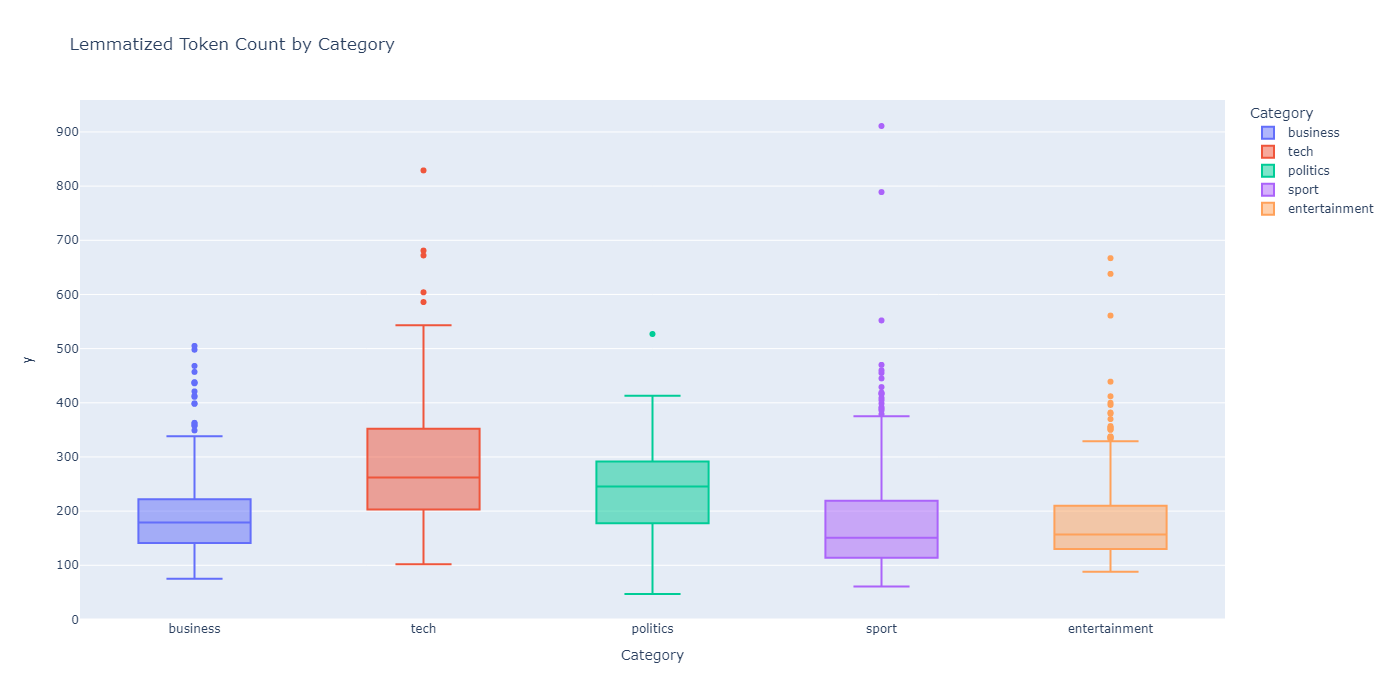

In [558]:
token_count = train['lemmas'].apply(len)
token_count
fig = px.box(train, x = 'Category', y = token_count, color = 'Category', title = 'Lemmatized Token Count by Category', height = 700)
fig.show()

In [559]:
# print(train['topic'].head())

In [560]:
labels = list(train['Category'].unique())
labels

['business', 'tech', 'politics', 'sport', 'entertainment']

Let's reuse the function that we wrote in the Week 2 autograded assignment, 'label_permute_compare', to assign the category labels in the highest accuracy manner after the clustering methods have built five unlabeled clusters.

In [561]:
def label_permute_compare(ytdf, yp , n=5):
    """
    ytdf: labels dataframe object
    yp: clustering label prediction output
    Returns permuted label order and accuracy. 
    Example output: (3, 4, 1, 2, 0), 0.74 
    """
    perms = list(itertools.permutations(list(range(n))))
    acc = []
    
    for i in range(len(perms)):
        mapdict = dict(zip(labels, list(perms[i])))
        yt = ytdf['Category'].apply(lambda x: mapdict[x])
        acc.append(accuracy_score(yt,yp))
    
    idx = np.argmax(acc)    
    return perms[idx], acc[idx]

There are several prudent options for natural language processing techniques, and today we shall implement one called 'Term Frequency - Inverse Document Frequency', or TF-IDF for short. TF-IDF is primarily used for deciding how important a word or token is to a document within a corpus of texts. There are two main components of the technique, Term Frequency and Inverse Document Frequency. Term Frequency refers to the concept of how many counts of a token/word/term appear within a single document, which is a measure of how important that term is to the document, so we could say that the term's weight is proportional to its intra-term presence. Inverse Document Frequency is a counterbalance that punishes terms for being used across the span of documents in the corpus. If a term is used in many documents, then it is going to be a poor differentiator of relevancy; stopword lists attempt to ameliorate this to some degree by pruning out words that are known to almost always have little value in discerning document specificity. IDF can be thought of as a measure of inter-term presence where the term's weight decreases logarithmically as it becomes more popular. 

In [562]:
# Join the lemmatized tokens into a string for each row
train['lemmas_str'] = train['lemmas'].apply(lambda x: ' '.join(x))

# Fit and transform the vectorizer on the lemmatized text
vectorizer = TfidfVectorizer(max_features = 1000)
tfidf = vectorizer.fit_transform(train['lemmas_str'])

Now that we have implemented TF-IDF on our vectorized lemmas, we would like to employ a Non-negative Matrix Factorization method, also known as NMF. NMF can be a very handy tool for dimensionality reduction and feature extraction, which help our model run in a performant manner. NMF takes the inital matrix, D, in which the columns are representative of the observations and the rows pertain to the predictors, and breaks it down into two smaller matrices, B and C. B is a matrix of the basis vectors and C is a matrix holding the coefficients corresponding to the importance of the vectors in B. This allows us to work with smaller input sizes, have a sparse data representation, and potentially remove features that seem relatively unimportant by using the basis vectors weightings to prune.   

In [563]:
# Fit the NMF model on the TF-IDF matrix
num_topics = 5
nmf = NMF(n_components = num_topics, random_state = 1234)
nmf.fit(tfidf)

# Store topic-word matrix and document-topic matrix
topic_word_matrix = nmf.components_
doc_topic_matrix = nmf.transform(tfidf)

# Assign the topic with highest weight to each document
train['topic'] = doc_topic_matrix.argmax(axis = 1)

# Test label assigner
label_permute_compare(train, train['topic'] , n = 5)

((3, 4, 0, 1, 2), 0.8914405010438413)

Our initial results are already looking quite promising! ~89% is nothing to sneeze at, but let's do some hyperparameter tuning and try to make our model even stronger. First, we will target the hyperparameters in the TF-IDF vectorizer. The attempted hyperparameter values are in the comments above the code where they were tried.

In [564]:
# Join the lemmatized tokens into a string for each row
train['lemmas_str'] = train['lemmas'].apply(lambda x: ' '.join(x))

# Preprocess the raw text
# Tuning tries: max_df: .7 to .99 incremented by 0.01, min_df from 1 to 5 incremented by 1
vectorizer = TfidfVectorizer(max_features = 10000, max_df = .90, min_df = 2) 

# Fit and transform the vectorizer on the lemmatized text
tfidf = vectorizer.fit_transform(train['lemmas_str'])

# Fit the NMF model on the TF-IDF matrix
num_topics = 5
nmf = NMF(n_components = num_topics, random_state = 1234)
nmf.fit(tfidf)

# Store topic-word matrix and document-topic matrix
topic_word_matrix = nmf.components_
doc_topic_matrix = nmf.transform(tfidf)

# Assign the topic with highest weight to each document
train['topic'] = doc_topic_matrix.argmax(axis = 1)

# Test label assigner
label_permute_compare(train, train['topic'] , n = 5)

((2, 4, 1, 0, 3), 0.9206680584551148)

After trying many values of max_df, anything 0.9 or higher all give the highest accuracy. Setting min_df to anything other than 2 will decrease the model's accuracy. Increasing max_features also seemed to boost the accuracy up until 10000, beyond that had no impact. By tuning these hyperparameters in the TF-IDF vectorizer, we were able to increase the model accuracy by about three percentage points, from 89% to 92%. Next, we will try tuning the hyperparameters in the NMF function.

In [565]:
# Join the lemmatized tokens into a string for each row
train['lemmas_str'] = train['lemmas'].apply(lambda x: ' '.join(x))

# Preprocess the raw text
vectorizer = TfidfVectorizer(max_features = 10000, max_df = .90, min_df = 2) 

# Fit and transform the vectorizer on the lemmatized text
tfidf = vectorizer.fit_transform(train['lemmas_str'])

# Tried:
# All solvers, all loss metrics, all inits
# alpha_W/alpha_H from 0.00001 to 0.05 by factors of 10 and 5

# Fit the NMF model on the TF-IDF matrix
num_topics = 5
nmf = NMF(n_components = num_topics, solver = 'mu', beta_loss = 'kullback-leibler', alpha_W = 0.01, alpha_H = 0.05, l1_ratio = 0.001, init='nndsvdar', random_state = 1234)
nmf.fit(tfidf)

# Store topic-word matrix and document-topic matrix
topic_word_matrix = nmf.components_
doc_topic_matrix = nmf.transform(tfidf)

train['topic'] = doc_topic_matrix.argmax(axis = 1)

best_perm, accuracy = label_permute_compare(train, train['topic'] , n = 5)
print(best_perm, accuracy)

(2, 4, 1, 0, 3) 0.9554627696590118


After tuning the hyperparameters in the Non-negative Matrix Factorization model, chiefly switching the solver from 'Coordinate Descent' to 'Multiplicative Update' and changing the beta loss function from 'Frobenius' to 'Kullback-Leibler', we are able to further increase the model accuracy from 92% all the way up to 95.5%, which is certainly respectable!

In [566]:
# param_grid = {
#     'alpha_W': [0.0001, 0.001, 0.01, 0.05, 0.1, 0.2],
#     'alpha_H': [0.0001, 0.001, 0.01, 0.05, 0.1, 0.2],
#     'l1_ratio': [0, 0.25, 0.5, 0.75, 1],
# }

# # Define the model to use
# nmf = NMF(n_components = num_topics, random_state = 1234)

# # Define the GridSearchCV object
# grid_search = GridSearchCV(
#     estimator=nmf, 
#     param_grid=param_grid,
#     cv=5,  # Use 5-fold cross-validation
#     scoring='accuracy',  # Use mean squared error as the evaluation metric
#     # n_jobs=-1,  # Use all available CPU cores
# )

# # Fit the GridSearchCV object on the TF-IDF matrix
# grid_search.fit(tfidf, train['Category'])

# # Get the best hyperparameters and model
# best_nmf = grid_search.best_estimator_
# best_params = grid_search.best_params_

# print("Best hyperparameters:", best_params)
# print("Best score (mean squared error):", -grid_search.best_score_)

At long last, it's time to turn our attention to the test dataset. We will implement the same process with TF-IDF and NMF as with the training set, but keeping the hyperparameters from our best trained model. 

In [567]:
cleaner(test, 'Text')
tokens(test, 'go')

# Join the lemmatized tokens into a string for each row
test['lemmas_str'] = test['lemmas'].apply(lambda x: ' '.join(x))

# Preprocess the raw text
test_vectorizer = TfidfVectorizer(max_features = 10000, max_df = .90, min_df = 2) 

# Fit and transform the vectorizer on the lemmatized text
test_tfidf = test_vectorizer.fit_transform(test['lemmas_str'])

# Fit the NMF model on the TF-IDF matrix
num_topics = 5
test_nmf = NMF(n_components = num_topics, solver = 'mu', beta_loss = 'kullback-leibler', alpha_W = 0.01, alpha_H = 0.05, l1_ratio = 0.001, init='nndsvdar', random_state = 1234)
test_nmf.fit(test_tfidf)

# Store topic-word matrix and document-topic matrix
test_topic_word_matrix = test_nmf.components_
test_doc_topic_matrix = test_nmf.transform(test_tfidf)

# Assign the topic with highest weight to each document
test['topic'] = test_doc_topic_matrix.argmax(axis = 1)

We have our trained model and its predictions, but if we think back to the EDA section, we will remember that we do not have access to the actual results. We will need to create a submission csv and upload it to the Kaggle competition to get our score back.

In [568]:
# Retrieve labels in the order that performed best
best = dict(zip(best_perm, labels))

# Build submission dataframe based on sample csv
submission = pd.DataFrame()
submission['ArticleId'] = test['ArticleId']
submission['Category'] = test['topic'].apply(lambda x: best[x])

print(submission.head())

submission.to_csv('submission.csv', index=False)

   ArticleId       Category
0       1018          sport
1       1319  entertainment
2       1138          sport
3        459       business
4       1020          sport


Our submission accuracy ended up being about 93%, which is a respectable scoring. Note that we would expect the test scores to be a little bit lower than the training scores, since the model hasn't seen this data before.

Supervised Learning

Let's see if we can get similar or better results by switching over to a supervised learning method, Random Forest. Like before, we will use TF-IDF and then feed the results into our random forest model instead of using NMF.

In [569]:
# Preprocess the raw text
rf_vectorizer = TfidfVectorizer(max_features=1000)

# Fit and transform the vectorizer on the lemmatized text
rf_tfidf = rf_vectorizer.fit_transform(train['lemmas_str'])

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(rf_tfidf, train['Category'], test_size=0.2, random_state = 1234)

# Define the Random Forest classifier
rf = RandomForestClassifier(n_estimators = 100, random_state = 1234)

# Train the classifier on the training set
rf.fit(X_train, y_train)

# Predict the categories for the test set
y_pred = rf.predict(X_test)

# Evaluate the accuracy of the model
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.9548611111111112


Submit supervised model results to Kaggle:

In [570]:
# Build submission dataframe based on sample csv
super_submission = pd.DataFrame()
super_submission['ArticleId'] = test['ArticleId']
super_submission['Category'] = test['topic'].apply(lambda x: best[x])

print(super_submission.head())

super_submission.to_csv('super_submission.csv', index=False)

   ArticleId       Category
0       1018          sport
1       1319  entertainment
2       1138          sport
3        459       business
4       1020          sport


Another successful model creation, with an accuracy of around ~95% on our test set and ~92% with the Kaggle scoring. Let's try out another supervised modeling technique, K means, and try to get similar performance. 

In [571]:
from sklearn.cluster import KMeans

# Preprocess the raw text
km_vectorizer = TfidfVectorizer(max_features=1000)

# Fit and transform the vectorizer on the lemmatized text
km_tfidf = km_vectorizer.fit_transform(train['lemmas_str'])

# Define the Random Forest classifier
km = KMeans(n_clusters = 5, init = 'k-means++', algorithm = 'lloyd', random_state = 1234)

# Train the classifier on the training set
train_yhat = km.fit_predict(km_tfidf)
train_y = pd.DataFrame(train, columns=['Category'])

# Predict the categories for the test set
best_perm, accuracy = label_permute_compare(train_y, train_yhat)
print(best_perm, accuracy)

# Evaluate the accuracy of the model
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", round(accuracy, 2))

C:\Users\jshap\AppData\Roaming\jupyterlab-desktop\jlab_server\lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning:

The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning



(3, 4, 0, 1, 2) 0.8441196938065414
Accuracy: 0.95


We are able to achieve another solid model performance on the training data of 95%, let's now check it against the test data.

In [572]:
# Preprocess the raw text
km_vectorizer = TfidfVectorizer(max_features=1000)

# Fit and transform the vectorizer on the lemmatized text
km_tfidf = km_vectorizer.fit_transform(test['lemmas_str'])

# Define the Random Forest classifier
km = KMeans(n_clusters = 5, init = 'k-means++', algorithm = 'lloyd', random_state = 1234)

# Train the classifier on the training set
test_yhat = km.fit_predict(km_tfidf)

# Build submission file
test_submission = pd.DataFrame()
test_submission['ArticleId'] = test['ArticleId']
test_submission['Category'] = test['topic'].apply(lambda x: best[x])

print(submission.head())

submission.to_csv('submission.csv', index=False)

   ArticleId       Category
0       1018          sport
1       1319  entertainment
2       1138          sport
3        459       business
4       1020          sport


C:\Users\jshap\AppData\Roaming\jupyterlab-desktop\jlab_server\lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning:

The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning



Another submission with this model gives us a hearty 91% score. All in all, it seems that with a concerted effort, we are able to achieve excellent training and testing scores across a multitude of different modeling techniques, both in supervised and unsupervised domains.